# Install Dependencies

Gerekli Kütüphanelerin Kurulumu

In [53]:
%pip install numpy pandas scikit-learn matplotlib seaborn catboost


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Import Libraries

Kütüphanelerin İçe Aktarımı

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)

%matplotlib inline

# Load Data

Verilerin CSV Dosyadan Yüklenmesi

Bu dosyada ayraç virgül değil noktalı virgül (;) olduğu için sep=';' verilmesi gerekiyor. <br>

In [55]:
df = pd.read_csv('datasets/bank-additional-full.csv', sep=';')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Veri seti 41188 örneklemden oluşuyor. 21 sütun var. Bunların 20'si tahmin edici değişken, 1'i hedef değişken. <br>
Hedef değişkenimiz y. Müşterinin vadeli mevduat hesabı açıp açmadığını gösteriyor (yes / no). <br>
sınıflandırma (classification) problemi. <br><br>

age, duration, campaign, pdays, previous int64 tipinde. <br>
emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed float64 tipinde. Bunlar ekonomik göstergeler. <br>
Geri kalan 11 sütun object tipinde, yani kategorik. <br>

# Exploratory Data Analysis

Veri Seti keşfi

In [56]:
print(f"Dataset Shape: {df.shape}")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (41188, 21)
Number of Rows: 41188
Number of Columns: 21


In [57]:
display(df.head(10))
display(df.tail(10))

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
9,25,services,single,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41178,62,retired,married,university.degree,no,no,no,cellular,nov,thu,...,2,6,3,success,-1.1,94.767,-50.8,1.031,4963.6,yes
41179,64,retired,divorced,professional.course,no,yes,no,cellular,nov,fri,...,3,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41180,36,admin.,married,university.degree,no,no,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41181,37,admin.,married,university.degree,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41182,29,unemployed,single,basic.4y,no,yes,no,cellular,nov,fri,...,1,9,1,success,-1.1,94.767,-50.8,1.028,4963.6,no
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [58]:
display(df.describe())

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


duration'da max değer 4918 saniye, ortalama 258. Çok uç değerler var. <br>
campaign'de max 56, yani bir müşteri 56 kere aranmış. Bu da aykırı değer olabilir. <br>
pdays'in medyanı ve 75%'i 999. Bu 999 aslında "daha önce hiç aranmamış" anlamına geliyor, gerçek bir gün sayısı değil. <br>

## Target Variable

Hedef değişkenin dağılımı

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


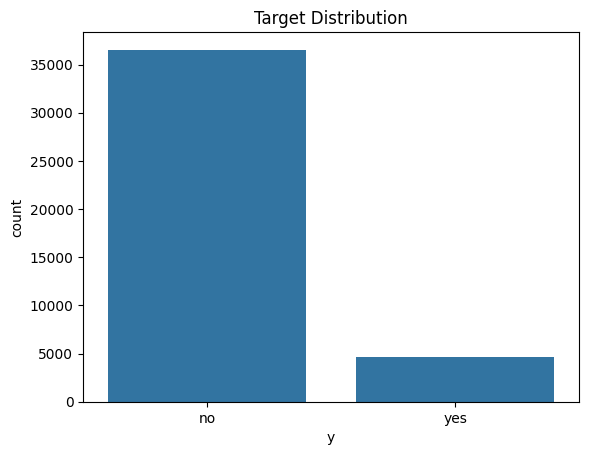

In [59]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="y")
plt.title("Target Distribution")
plt.show()

Veri çok dengesiz (imbalanced). Müşterilerin sadece %11.27'si yes demiş. <br>
Bu yüzden accuracy tek başına iyi bir metrik olmayacak. Model herkese "no" dese bile %88.7 accuracy alır. <br>
Precision, recall, F1 ve ROC-AUC'a da bakmak gerekiyor. <br>

## Missing Values

Eksik değer tespiti

In [60]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing)

,Missing Count,Missing Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0
day_of_week,0,0.0


Hiç null değer yok gibi görünüyor ama kategorik sütunlarda "unknown" diye bir değer var. <br>
Bu da aslında eksik veri demek. <br>

In [61]:
unknown = pd.DataFrame({
    "Unknown Count": (df == "unknown").sum(),
    "Unknown Percentage": ((df == "unknown").mean() * 100).round(2)
})

display(unknown[unknown["Unknown Count"] > 0])

,Unknown Count,Unknown Percentage
job,330,0.80
marital,80,0.19
education,1731,4.20
default,8597,20.87
housing,990,2.40
loan,990,2.40


default sütununda %20.87 unknown var. Çok yüksek. <br>
education'da %4.2, housing ve loan'da %2.4, job'da %0.8, marital'da %0.19 unknown var. <br>

## Duplicate Rows

Tekrarlayan satırların tespiti

In [62]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 12


12 tane tekrarlayan satır var. Bunlar silinmeli. <br>

## Unique Values

In [63]:
for column in df.columns:
    print(f"\n{column}")
    print("Unique Values:", df[column].nunique())
    print(df[column].unique()[:12])


age
Unique Values: 78
[56 57 37 40 45 59 41 24 25 29 35 54]

job
Unique Values: 12
['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']

marital
Unique Values: 4
['married' 'single' 'divorced' 'unknown']

education
Unique Values: 8
['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']

default
Unique Values: 3
['no' 'unknown' 'yes']

housing
Unique Values: 3
['no' 'yes' 'unknown']

loan
Unique Values: 3
['no' 'yes' 'unknown']

contact
Unique Values: 2
['telephone' 'cellular']

month
Unique Values: 10
['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep']

day_of_week
Unique Values: 5
['mon' 'tue' 'wed' 'thu' 'fri']

duration
Unique Values: 1544
[261 149 226 151 307 198 139 217 380  50  55 222]

campaign
Unique Values: 42
[ 1  2  3  4  5  6  7  8  9 10 11 12]

pdays
Unique Values: 27
[999   6   4   3   5   1   0  10   7   8

job'da 12, education'da 8, month'ta 10 farklı değer var. <br>
default sütununda yes sadece birkaç tane. <br>
poutcome'da nonexistent, failure ve success var. Önceki kampanyanın sonucunu gösteriyor. <br>

In [64]:
print(df["default"].value_counts())

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64


default'ta sadece 3 tane yes var. Geri kalanı no veya unknown. Bu sütunun neredeyse hiç bilgi taşımadığı görülüyor. <br>

## Numerical distributions

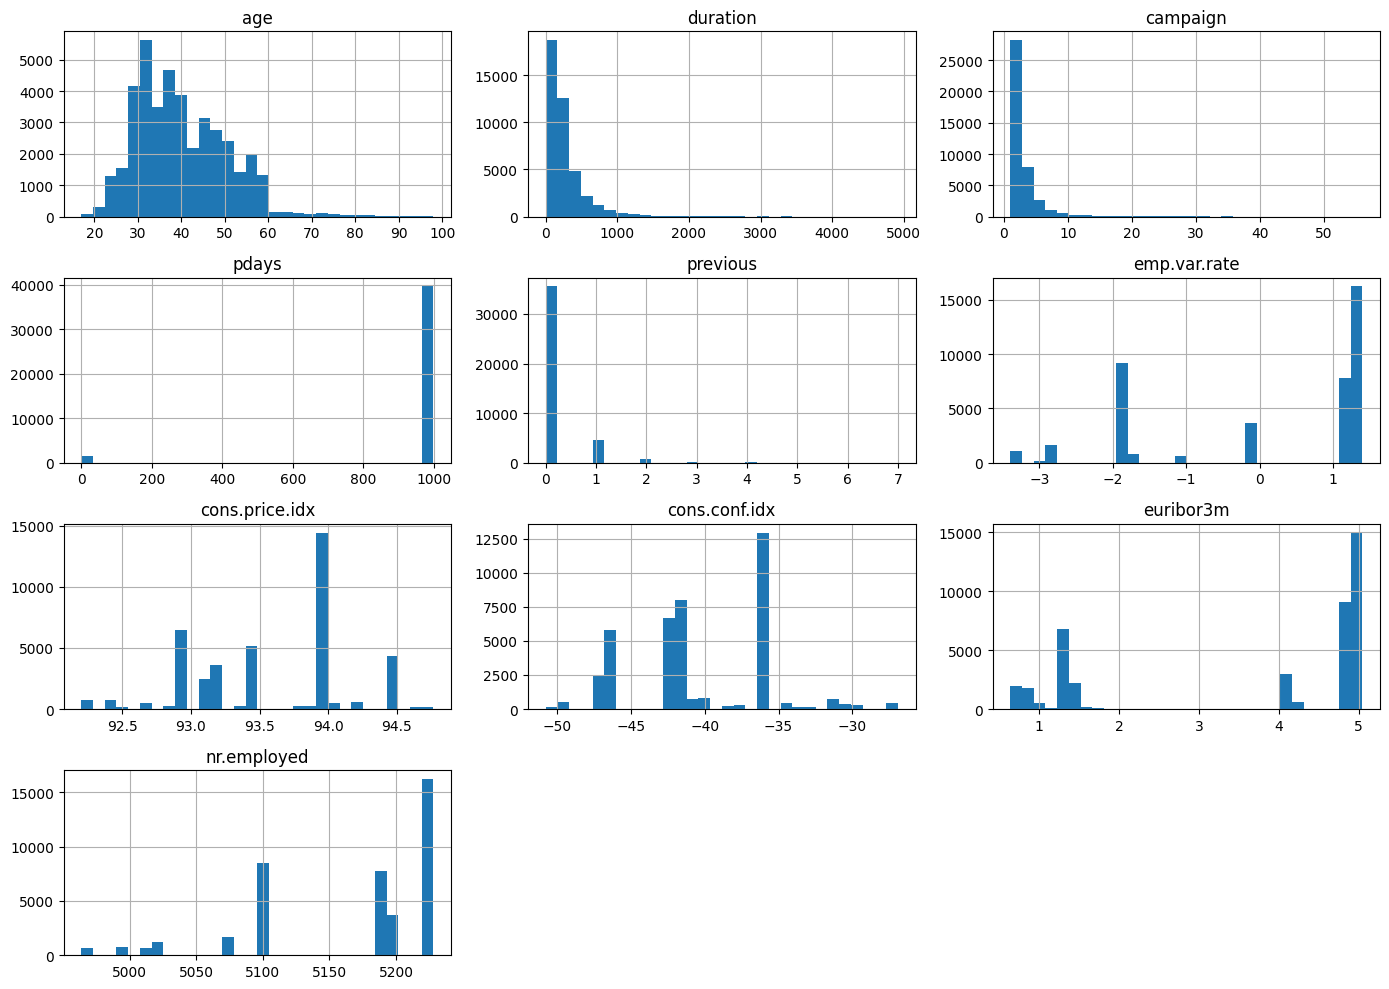

In [65]:
df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

age 25-60 arasında yoğunlaşmış. </br>
duration ve campaign sağa çarpık, uzun bir kuyrukları var. </br>
pdays neredeyse tamamen 999'da toplanmış. </br>
Ekonomik göstergeler sürekli değil, birkaç belli değerde toplanmış. Çünkü bunlar aylık/çeyreklik değerler. </br>

## Outliers

Outlier tespiti

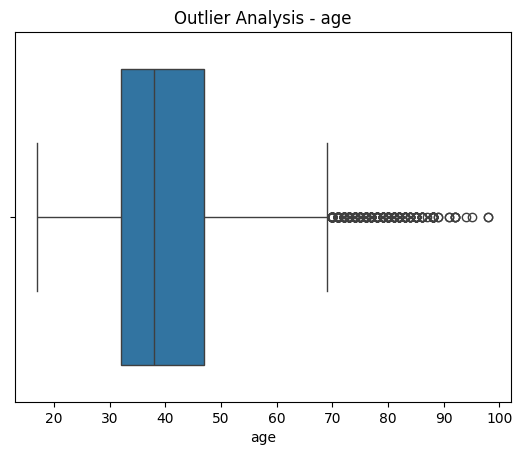

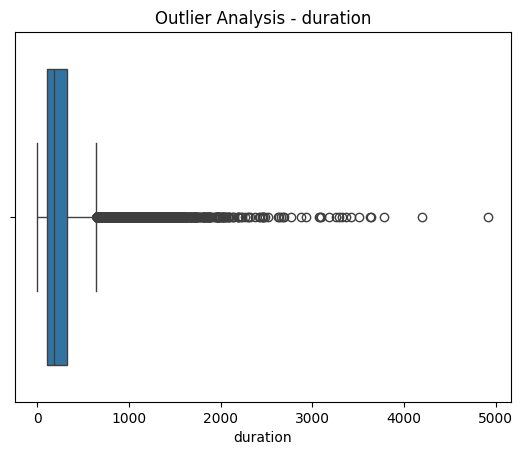

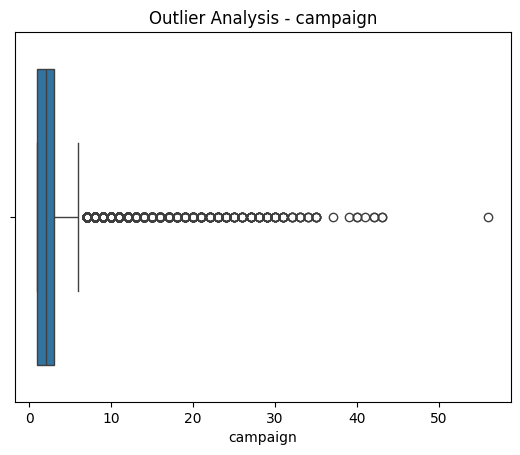

In [66]:
for column in ["age", "duration", "campaign"]:
    sns.boxplot(x=df[column])
    plt.title(f"Outlier Analysis - {column}")
    plt.show()

## Categorical Features vs Target

Kategorik değişkenlere göre yes oranı

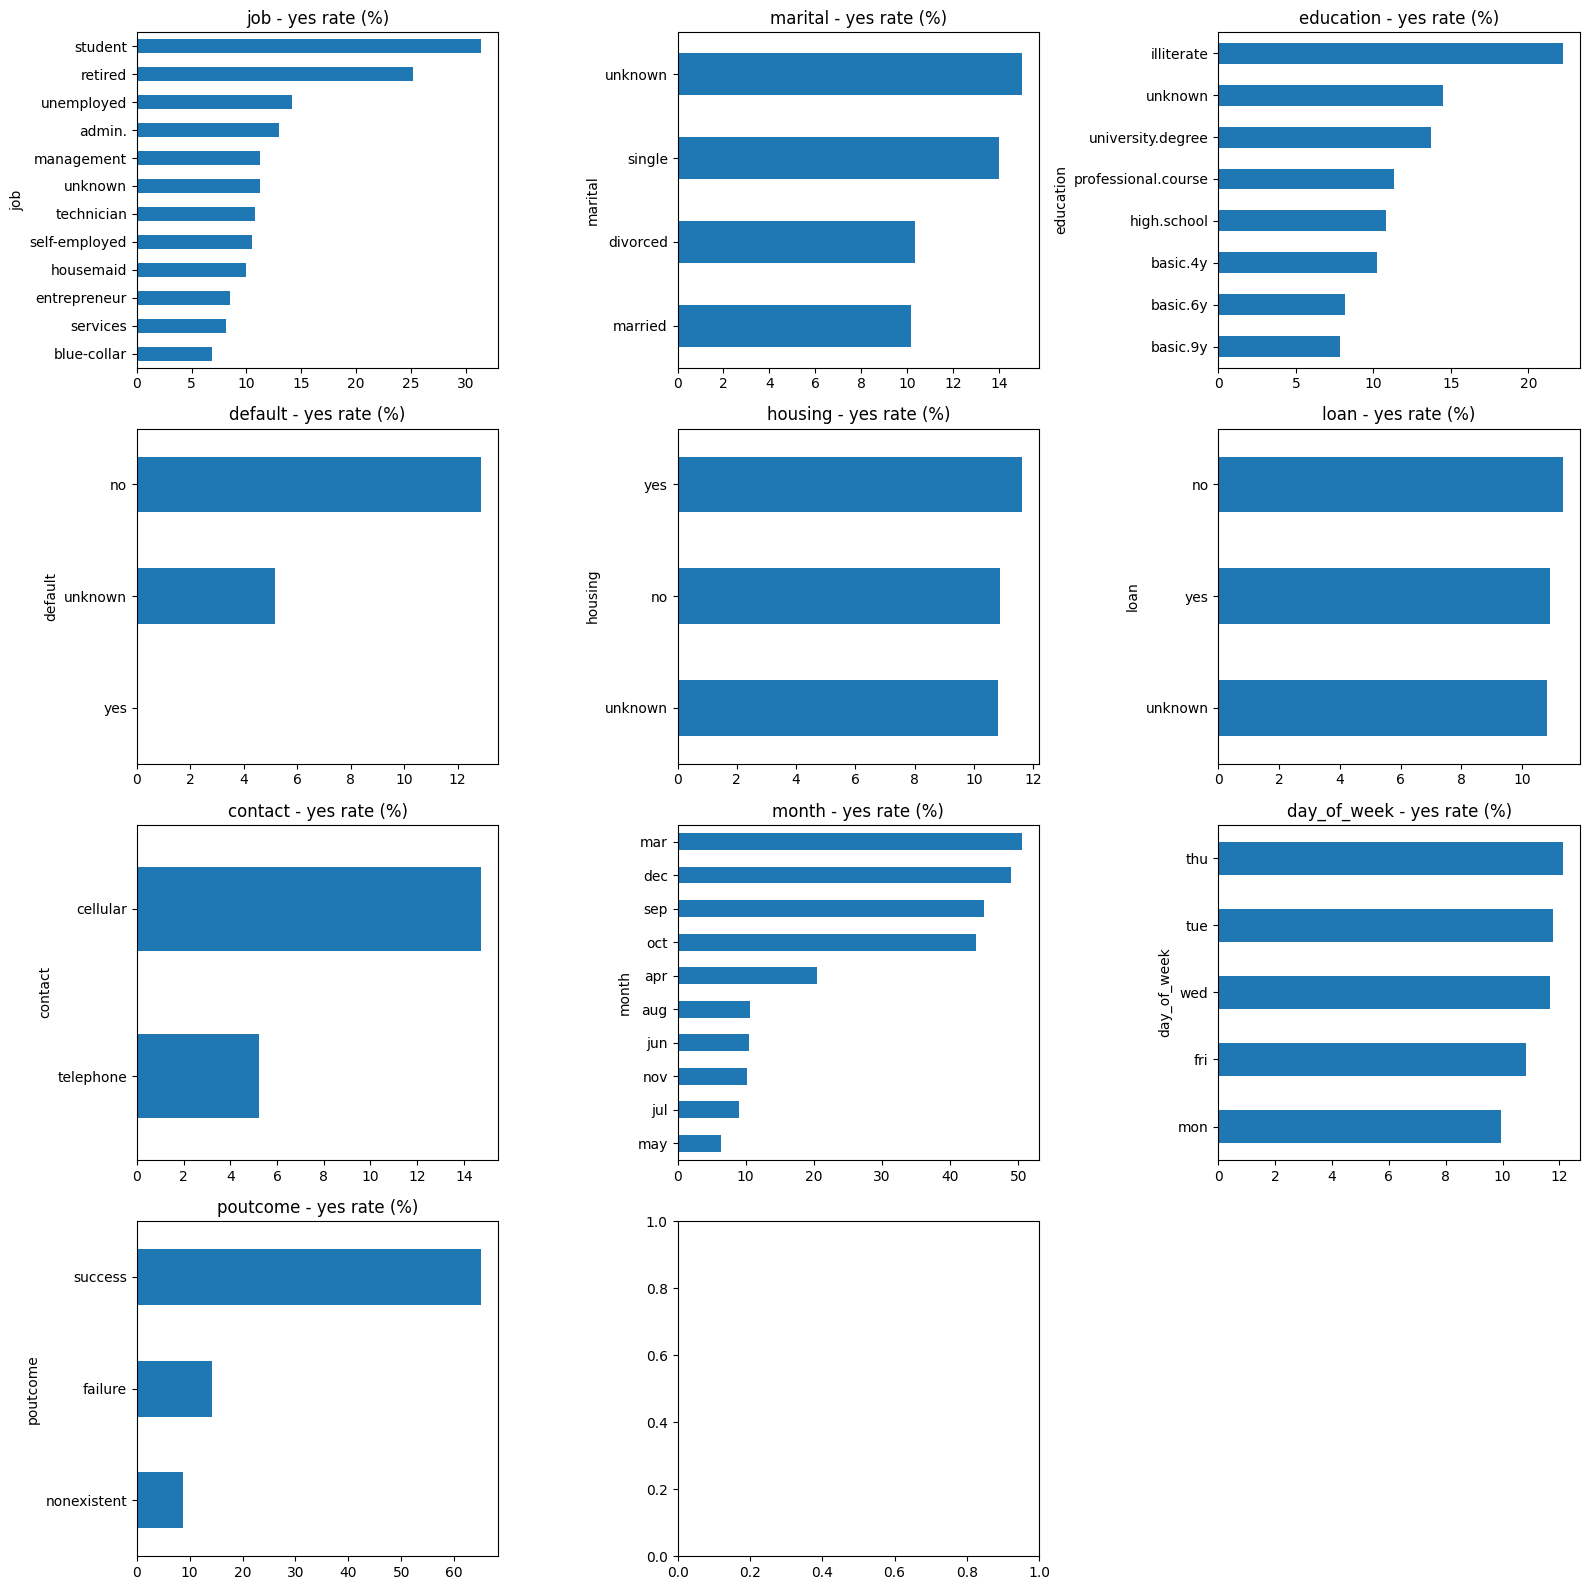

In [67]:
categorical_columns = df.select_dtypes(include="object").columns.drop("y")

fig, axes = plt.subplots(4, 3, figsize=(16, 16))

for ax, column in zip(axes.flatten(), categorical_columns):
    rate = (df["y"] == "yes").groupby(df[column]).mean().sort_values() * 100
    rate.plot(kind="barh", ax=ax)
    ax.set_title(f"{column} - yes rate (%)")

axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

student ve retired olanların yes oranı diğer mesleklere göre çok daha yüksek. <br>
poutcome success olanlarda yes oranı %65 civarında. Önceki kampanyaya evet diyen tekrar evet diyor. <br>
cellular ile aranlar telephone ile arananlara göre daha çok yes demiş. <br>
mar, sep, oct, dec aylarında yes oranı yüksek ama bu aylarda zaten az arama yapılmış. <br>

## Korrelation Matrix

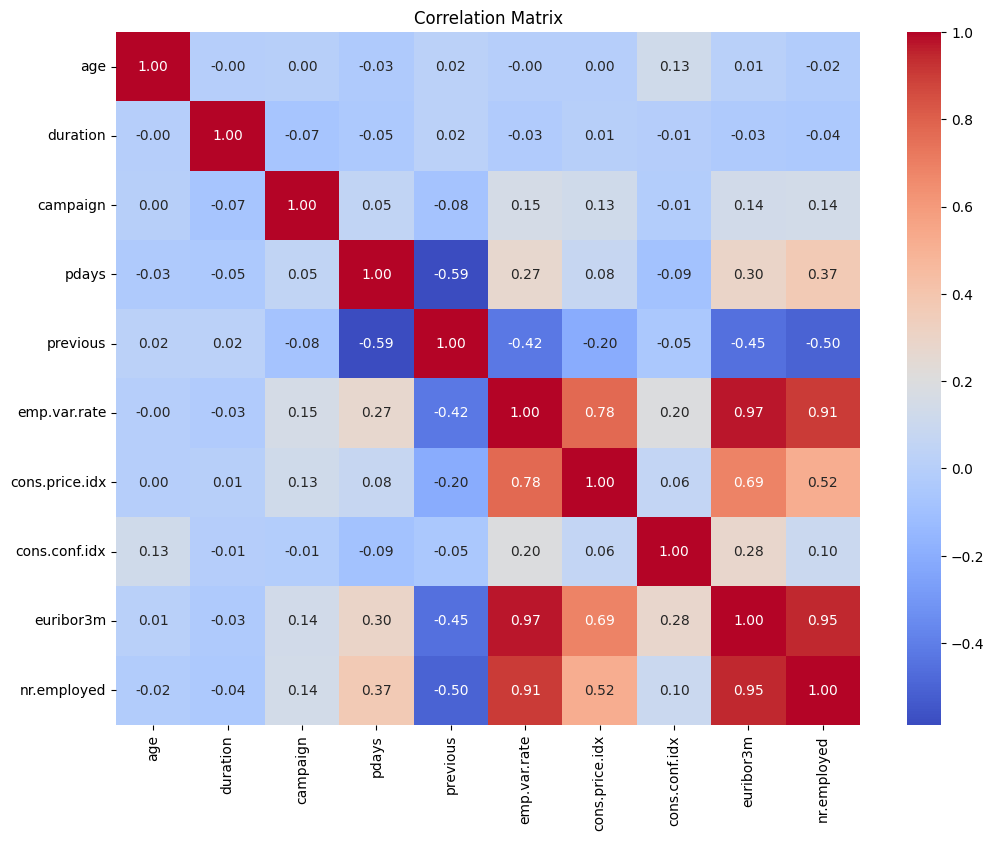

In [68]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

emp.var.rate, euribor3m ve nr.employed arasında çok yüksek korelasyon var (0.90 üstü). <br>
Bunlar neredeyse aynı bilgiyi taşıyor. Hepsini tutmak linear modellerde sorun çıkarabilir (multicollinearity). <br>

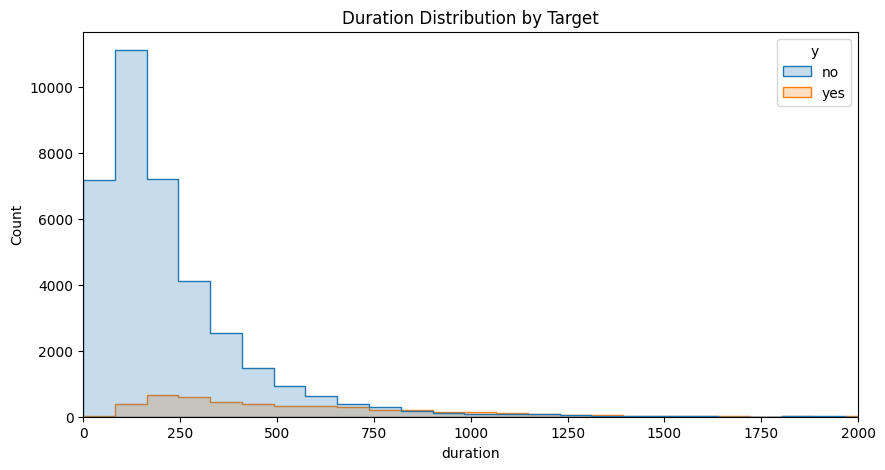

In [69]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="duration", hue="y", bins=60, element="step")

plt.title("Duration Distribution by Target")
plt.xlim(0, 2000)
plt.show()

Görüşme süresi uzadıkça yes oranı çok artıyor. Ama burada bir sorun var. <br>
duration, görüşme bittikten sonra belli olan bir bilgi. Görüşmeden önce kimi arayacağımıza karar verirken bu bilgiyi bilemeyiz. <br>
Veri setinin açıklamasında da duration'ın gerçekçi bir model için çıkarılması gerektiği yazıyor. <br>

# Data Cleaning

Veri temizleme işlemleri

## Renaming Column Names

Sütun isimlerindeki noktalar kullanımı zorlaştırdığı için alt çizgiye çevrildi. <br>

In [70]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(".", "_")
)
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y']


## Duplicate Values

Tekrarlayan satırların silinmesi

In [71]:
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate Rows after removal:", df.duplicated().sum())
print(f"New Dataset Shape: {df.shape}")

Duplicate Rows after removal: 0
New Dataset Shape: (41176, 21)


## Removing Leakage Column

duration sütunu data leakage oluşturduğu için silindi. <br>
Bunu bırakırsak model çok yüksek skorlar verir ama gerçek hayatta kullanılamaz. <br>

In [72]:
df = df.drop(columns=["duration"])
print(f"New Dataset Shape: {df.shape}")

New Dataset Shape: (41176, 20)


## Removing Default Column

default sütununda sadece 3 tane yes var, %20'si unknown. Bir bilgi taşımadığı için silindi. <br>

In [73]:
df = df.drop(columns=["default"])
print(f"New Dataset Shape: {df.shape}")

New Dataset Shape: (41176, 19)


## Unknown Values

unknown değerler NaN'a çevrildi. Böylece pandas'ın eksik veri fonksiyonları kullanılabilir. <br>
Doldurma işlemi data leakage olmaması için split'ten sonra yapılacak. <br>

In [74]:
df = df.replace("unknown", np.nan)

missing_analysis = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_analysis[missing_analysis["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
job,330,0.80
marital,80,0.19
education,1730,4.20
housing,990,2.40
loan,990,2.40


## Feature Engineering

### pdays

pdays'deki 999 değeri "daha önce aranmamış" demek. Bunu sayı olarak bırakırsak model 999 günü gerçek bir değer sanar. <br>
Bunun yerine previously_contacted diye yeni bir sütun oluşturuldu (1 = daha önce aranmış, 0 = aranmamış). pdays sütunu silindi. <br>

In [75]:
df["previously_contacted"] = (df["pdays"] != 999).astype(int)
df = df.drop(columns=["pdays"])

print(df["previously_contacted"].value_counts())

previously_contacted
0    39661
1     1515
Name: count, dtype: int64


Müşterilerin sadece 1515'i daha önce aranmış. <br>

### Correlated Economic Features

emp_var_rate ve nr_employed, euribor3m ile çok yüksek korelasyonlu. <br>
Üçünden sadece euribor3m bırakıldı, diğer ikisi silindi. <br>

In [76]:
print(df[["emp_var_rate", "euribor3m", "nr_employed"]].corr())

df = df.drop(columns=["emp_var_rate", "nr_employed"])
print(df.columns.tolist())

              emp_var_rate  euribor3m  nr_employed
emp_var_rate      1.000000   0.972244     0.906949
euribor3m         0.972244   1.000000     0.945146
nr_employed       0.906949   0.945146     1.000000
['age', 'job', 'marital', 'education', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'y', 'previously_contacted']


### Target Encoding

y sütunu yes = 1, no = 0 olacak şekilde sayıya çevrildi. <br>

In [77]:
df["y"] = df["y"].map({"no": 0, "yes": 1})
print(df["y"].value_counts())

y
0    36537
1     4639
Name: count, dtype: int64


# Dataset Splitting

Veri setinin eğitim ve test setlerine ayrılması <br>
Oran 80-20 olacak şekilde ayarlanacak. <br>
Veri dengesiz olduğu için stratify=y kullanıldı. Böylece train ve test'te yes oranı aynı kalıyor. <br>

In [78]:
X = df.drop(columns=["y"])
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Train yes oranı:", y_train.mean().round(4))
print("Test yes oranı:", y_test.mean().round(4))

Train: (32940, 16)
Test: (8236, 16)
Train yes oranı: 0.1127
Test yes oranı: 0.1127


Veriler bölündükten sonra 32940 train ve 8236 test örneklemi var. İkisinde de yes oranı %11.27. <br>

# Preprocessing

Veriyi ön işleme

In [79]:
numeric_features = [
    "age",
    "campaign",
    "previous",
    "cons_price_idx",
    "cons_conf_idx",
    "euribor3m"
]

binary_features = [
    "contact",
    "previously_contacted"
]

nominal_features = [
    "job",
    "marital",
    "housing",
    "loan",
    "month",
    "day_of_week",
    "poutcome"
]

ordinal_features = [
    "education"
]

## Filling Missing Values


- job, marital ve education: az sayıda eksik var, train'deki en çok görülen değerle (mode) dolduruldu. <br>
- housing ve loan: ikisinde de tam olarak aynı satırlarda eksik var. Bunları doldurmak yerine "unknown" ayrı bir kategori olarak bırakıldı. <br>

In [80]:
print("housing ve loan aynı satırlarda mı eksik:", (X_train["housing"].isnull() == X_train["loan"].isnull()).all())

housing ve loan aynı satırlarda mı eksik: True


In [81]:
for column in ["job", "marital", "education"]:
    mfv = X_train[column].mode()[0]
    print(f"{column} most common value: {mfv}")

    X_train[column] = X_train[column].fillna(mfv)
    X_test[column] = X_test[column].fillna(mfv)

for column in ["housing", "loan"]:
    X_train[column] = X_train[column].fillna("unknown")
    X_test[column] = X_test[column].fillna("unknown")

print("\nX_train empty values:", X_train.isnull().sum().sum())
print("X_test empty values:", X_test.isnull().sum().sum())

job most common value: admin.
marital most common value: married
education most common value: university.degree

X_train empty values: 0
X_test empty values: 0


Train verisinden hesaplanan değerler test verisine de uygulandı. <br>

## Outlier Handling

 campaign sütununda çok uç değerler var (56 arama gibi). <br>
Satırları silmek yerine capping yapıldı. Yani üst sınırın üstündeki değerler üst sınıra eşitlendi. <br>
Sınır train verisinin %99'luk değerine göre belirlendi. <br>

In [82]:
outlier_results = []

for column in ["age", "campaign"]:

    Q1 = X_train[column].quantile(0.25)
    Q3 = X_train[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[column] < lower_bound) |
        (X_train[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(X_train) * 100
    })

display(pd.DataFrame(outlier_results).round(2))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,9.5,69.5,383,1.16
1,campaign,-2.0,6.0,1911,5.80


IQR'a göre campaign'de çok fazla outlier çıkıyor çünkü değerlerin çoğu 1-3 arasında. <br>
IQR sınırı (6) çok sıkı olduğu için %99'luk sınır kullanıldı. <br>
age'deki yaşlı müşteriler ise gerçek veriler, onlara dokunulmadı. <br>

In [83]:
campaign_cap = X_train["campaign"].quantile(0.99)
print("Campaign cap:", campaign_cap)

X_train["campaign"] = X_train["campaign"].clip(upper=campaign_cap)
X_test["campaign"] = X_test["campaign"].clip(upper=campaign_cap)

print("New max:", X_train["campaign"].max())

Campaign cap: 14.0
New max: 14


## Categorical Columns Processing

### Binary Encoding

contact sadece iki değer alıyor (cellular / telephone). One-hot yerine direkt 0-1'e çevrildi. <br>

In [84]:
X_train["contact"] = (X_train["contact"] == "cellular").astype(int)
X_test["contact"] = (X_test["contact"] == "cellular").astype(int)

### Ordinal Encoding

education sıralı bir değişken. illiterate en düşük, university.degree en yüksek. <br>
professional.course'u high.school ile university.degree arasına koyduk. <br>

In [85]:
education_levels = [
    "illiterate",
    "basic.4y",
    "basic.6y",
    "basic.9y",
    "high.school",
    "professional.course",
    "university.degree"
]

ordinal_encoder = OrdinalEncoder(categories=[education_levels], dtype=int)
X_train["education"] = ordinal_encoder.fit_transform(X_train[["education"]])
X_test["education"] = ordinal_encoder.transform(X_test[["education"]])

print(X_train["education"].value_counts().sort_index())

education
0       18
1     3346
2     1817
3     4831
4     7605
5     4213
6    11110
Name: count, dtype: int64


artık education sütununda 0-6 arası değerler var. <br>

### One-Hot Encoding

CatBoost modelinde kategorik verileri direkt kullanacağımız için encoding öncesi halini kaydediyoruz. <br>
Geri kalan nominal sütunlara one-hot encoding uygulandı. <br>

In [86]:
X_train_raw = X_train.copy()
X_test_raw = X_test.copy()

X_train = pd.get_dummies(
    X_train,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Train columns:", X_train.shape[1])
print("Test columns:", X_test.shape[1])
print("Columns match:", X_train.columns.equals(X_test.columns))

Train columns: 40
Test columns: 40
Columns match: True


encoding yapıldıktan sonra sütun sayısı 40'a çıktı. <br>

In [87]:
X_train.head(10)

,age,education,contact,campaign,previous,cons_price_idx,cons_conf_idx,euribor3m,previously_contacted,job_blue-collar,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
36444,24,5,1,2,1,92.963,-40.8,1.262,0,0,...,0,0,0,0,0,0,1,0,0,0
1233,32,5,0,1,0,93.994,-36.4,4.855,0,1,...,1,0,0,0,0,1,0,0,1,0
24104,33,6,0,1,0,93.200,-42.0,4.245,0,0,...,0,1,0,0,0,1,0,0,1,0
15513,38,3,0,4,0,93.918,-42.7,4.957,0,0,...,0,0,0,0,0,0,0,0,1,0
17912,39,4,1,4,0,93.918,-42.7,4.961,0,0,...,0,0,0,0,0,0,1,0,1,0
8504,43,1,0,4,0,94.465,-41.8,4.864,0,1,...,0,0,0,0,0,0,0,1,1,0
24130,57,3,1,1,0,93.200,-42.0,4.191,0,1,...,0,1,0,0,1,0,0,0,1,0
2680,55,6,0,2,0,93.994,-36.4,4.859,0,0,...,1,0,0,0,0,0,0,1,1,0
5824,36,3,0,4,0,93.994,-36.4,4.857,0,1,...,1,0,0,0,1,0,0,0,1,0
37518,57,4,1,1,0,92.201,-31.4,0.873,0,0,...,0,0,0,0,0,1,0,0,1,0


# Scaling

verilerin ölçeklenmesi

In [88]:
scaling_columns = numeric_features + ["education"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scaling_columns] = scaler.fit_transform(X_train[scaling_columns])
X_test_scaled[scaling_columns] = scaler.transform(X_test[scaling_columns])

Sayısal sütunlar ve education için StandardScaler kullanıldı. <br>
Scaler sadece train verisine fit edildi. <br>

In [89]:
X_train_scaled.head(10)

,age,education,contact,campaign,previous,cons_price_idx,cons_conf_idx,euribor3m,previously_contacted,job_blue-collar,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
36444,-1.532272,0.462514,1,-0.215894,1.657135,-1.057203,-0.062687,-1.357248,0,0,...,0,0,0,0,0,0,1,0,0,0
1233,-0.766955,0.462514,0,-0.653311,-0.348598,0.722038,0.887842,0.712567,0,1,...,1,0,0,0,0,1,0,0,1,0
24104,-0.671290,1.069930,0,-0.653311,-0.348598,-0.648202,-0.321922,0.361165,0,0,...,0,1,0,0,0,1,0,0,1,0
15513,-0.192967,-0.752318,0,0.658941,-0.348598,0.590881,-0.473142,0.771326,0,0,...,0,0,0,0,0,0,0,0,1,0
17912,-0.097303,-0.144902,1,0.658941,-0.348598,0.590881,-0.473142,0.773630,0,0,...,0,0,0,0,0,0,1,0,1,0
8504,0.285356,-1.967149,0,0.658941,-0.348598,1.534863,-0.278716,0.717751,0,1,...,0,0,0,0,0,0,0,1,1,0
24130,1.624660,-0.752318,1,-0.653311,-0.348598,-0.648202,-0.321922,0.330057,0,1,...,0,1,0,0,1,0,0,0,1,0
2680,1.433331,1.069930,0,-0.215894,-0.348598,0.722038,0.887842,0.714871,0,0,...,1,0,0,0,0,0,0,1,1,0
5824,-0.384296,-0.752318,0,0.658941,-0.348598,0.722038,0.887842,0.713719,0,1,...,1,0,0,0,1,0,0,0,1,0
37518,1.624660,-0.144902,1,-0.653311,-0.348598,-2.372219,1.967989,-1.581339,0,0,...,0,0,0,0,0,1,0,0,1,0


# Training Model

Modellerin Eğitilmesi


- Accuracy: doğru tahminlerin oranı. Veri dengesiz olduğu için yanıltıcı olabilir. <br>
- Precision: yes dediklerimizin ne kadarı gerçekten yes. <br>
- Recall: gerçek yes'lerin ne kadarını yakalayabildik. <br>
- F1: precision ve recall'un dengesi. <br>
- ROC-AUC: modelin yes ve no'yu ne kadar iyi ayırdığı. 0.5 rastgele tahmin, 1 mükemmel. <br><br>

Her model için aynı kodları tekrar yazmamak adına bir fonksiyon yazıldı. <br>

In [90]:
results = {}

def evaluate_model(name, model, X_tr=None, X_te=None):
    if X_tr is None:
        X_tr, X_te = X_train_scaled, X_test_scaled

    model.fit(X_tr, y_train)

    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    }

    print(f"{name} Model Results")
    print("--------------------------------")
    for metric, value in results[name].items():
        print(f"{metric:10}: {value:.4f}")

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["no", "yes"], yticklabels=["no", "yes"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    return model

## Logistic Regression

Önce class_weight vermeden normal bir Logistic Regression denendi. <br>

Logistic Regression Model Results
--------------------------------
Accuracy  : 0.8987
Precision : 0.6588
Recall    : 0.2101
F1        : 0.3186
ROC-AUC   : 0.7958


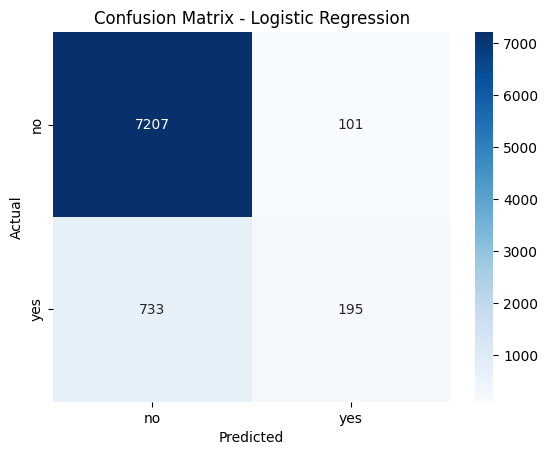

In [91]:
log_model = evaluate_model("Logistic Regression", LogisticRegression(max_iter=1000))

Logistic Regression Model Results
--------------------------------
Accuracy  : 0.8987<br>
Precision : 0.6588<br>
Recall    : 0.2101<br>
F1        : 0.3186<br>
ROC-AUC   : 0.7958<br><br><br>

Accuracy 0.8987 çıktı, ilk bakışta çok iyi görünüyor. Ama herkese no deseydik de 0.887 alacaktık. <br><br>
Recall sadece 0.21. Yani gerçekte yes diyen müşterilerin sadece %21'ini yakalayabiliyor.  <br><br>
Model dengesiz veri yüzünden çoğunlukla no demeyi öğrenmiş. <br>

## Logistic Regression (Balanced)

class_weight="balanced" ile az olan sınıfa (yes) daha fazla ağırlık verildi. <br>
Böylece model yes'leri kaçırdığında daha çok ceza alıyor. <br>

Logistic Regression (Balanced) Model Results
--------------------------------
Accuracy  : 0.8252
Precision : 0.3512
Recall    : 0.6509
F1        : 0.4562
ROC-AUC   : 0.7981


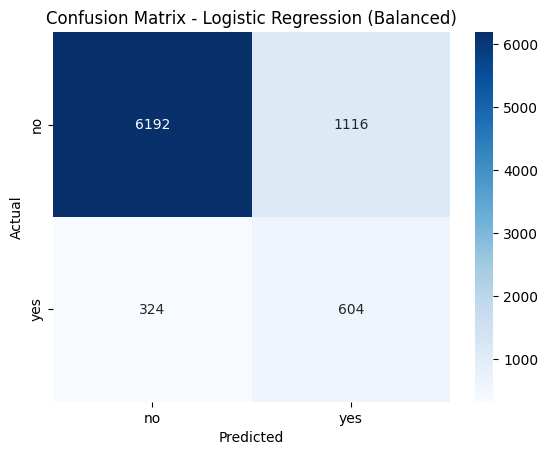

In [92]:
log_balanced_model = evaluate_model(
    "Logistic Regression (Balanced)",
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

Logistic Regression (Balanced) Model Results
--------------------------------
Accuracy  : 0.8252<br>
Precision : 0.3512<br>
Recall    : 0.6509<br>
F1        : 0.4562<br>
ROC-AUC   : 0.7981<br><br><br>

Accuracy 0.90'dan 0.83'e düştü ama recall 0.21'den 0.65'e çıktı. Artık yes diyenlerin %65'ini yakalıyoruz. <br><br>
Precision düştü, yani yes dediğimiz bazı müşteriler aslında no. Ama bir banka için birkaç fazla kişiyi aramak, potansiyel müşteriyi kaçırmaktan daha az maliyetli. <br><br>
F1 de 0.32'den 0.46'ya çıktı. Bundan sonraki modellerde de class_weight kullanıldı. <br>

In [93]:
coefficients = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Coefficient": log_balanced_model.coef_[0]
}).sort_values(by="Coefficient", ascending=False)

display(coefficients.head(10))
display(coefficients.tail(10))

,Feature,Coefficient
29,month_mar,1.189223
8,previously_contacted,1.187983
39,poutcome_success,0.781109
32,month_oct,0.664582
26,month_dec,0.463046
2,contact,0.438661
38,poutcome_nonexistent,0.403380
13,job_retired,0.359263
16,job_student,0.275285
5,cons_price_idx,0.264299


,Feature,Coefficient
31,month_nov,-0.094442
3,campaign,-0.109477
15,job_services,-0.117129
34,day_of_week_mon,-0.130424
9,job_blue-collar,-0.133671
25,month_aug,-0.136244
33,month_sep,-0.171679
18,job_unemployed,-0.206645
30,month_may,-0.671279
7,euribor3m,-0.925536


En pozitif katsayılar: month_mar, previously_contacted ve poutcome_success. Daha önce aranmış ve o kampanyada evet demiş müşteriler tekrar evet deme eğiliminde. <br>
En negatif katsayılar: euribor3m ve month_may. Faiz oranı (euribor) yüksekken insanlar daha az mevduat açmış. <br>
EDA'da da may ayında arama çok fazla ama yes oranı en düşük (%6.4) çıkmıştı. <br>

## Naive Bayes

Gaussian Naive Bayes, olasılık tabanlı çok basit ve hızlı bir model. Featureların birbirinden bağımsız olduğunu varsayıyor. <br>

Naive Bayes Model Results
--------------------------------
Accuracy  : 0.8731
Precision : 0.4348
Recall    : 0.4203
F1        : 0.4274
ROC-AUC   : 0.7631


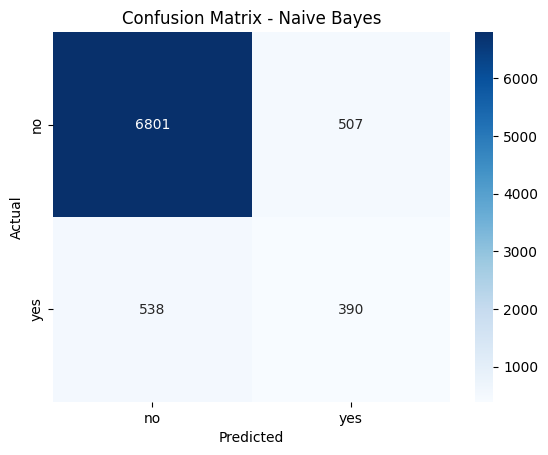

In [94]:
nb_model = evaluate_model("Naive Bayes", GaussianNB())

Naive Bayes Model Results
--------------------------------
Accuracy  : 0.8731<br>
Precision : 0.4348<br>
Recall    : 0.4203<br>
F1        : 0.4274<br>
ROC-AUC   : 0.7631<br><br><br>

Precision ve recall birbirine yakın çıktı. ROC-AUC ise şimdiye kadarki en düşük değer. <br>
Featurelar birbirinden bağımsız olmadığı için (örneğin month ve euribor3m ilişkili) Naive Bayes'in varsayımı tutmuyor. <br>

## KNN Classifier

KNN mesafe hesapladığı için scale edilmiş veri kullanıldı. <br>


KNN Model Results
--------------------------------
Accuracy  : 0.8963
Precision : 0.5984
Recall    : 0.2425
F1        : 0.3451
ROC-AUC   : 0.7728


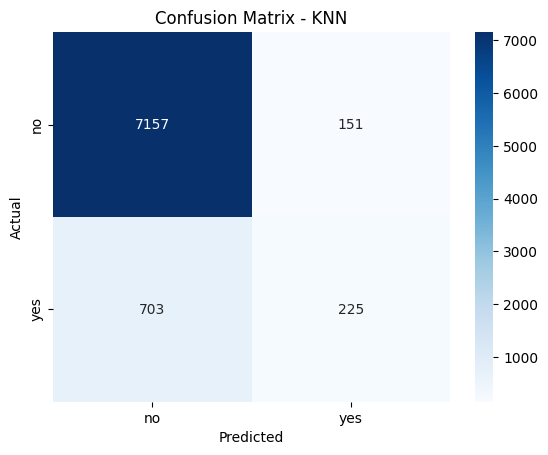

In [95]:
knn_model = evaluate_model("KNN", KNeighborsClassifier(n_neighbors=15))

KNN Model Results
--------------------------------
Accuracy  : 0.8963<br>
Precision : 0.5984<br>
Recall    : 0.2425<br>
F1        : 0.3451<br>
ROC-AUC   : 0.7728<br><br><br>

KNN'de class_weight parametresi yok. Bu yüzden normal Logistic Regression gibi çoğunlukla no diyor, recall 0.24'te kaldı. <br>
En yakın 15 komşunun çoğu zaten no olduğu için yes demesi zor. <br>

## Decision Tree Classifier

max_depth=6 ile ağacın overfit olması engellendi. class_weight='balanced' eklendi. <br>

Decision Tree Model Results
--------------------------------
Accuracy  : 0.8288
Precision : 0.3600
Recall    : 0.6681
F1        : 0.4679
ROC-AUC   : 0.8055


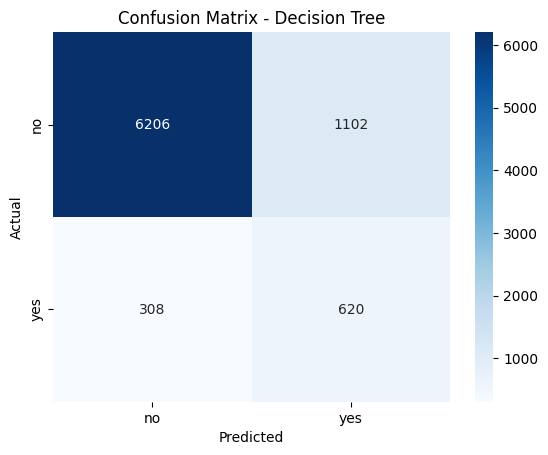

In [96]:
dt_model = evaluate_model(
    "Decision Tree",
    DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42)
)

Decision Tree Model Results
--------------------------------
Accuracy  : 0.8288<br>
Precision : 0.3600<br>
Recall    : 0.6681<br>
F1        : 0.4679<br>
ROC-AUC   : 0.8055<br><br><br>

Tek bir ağaç olmasına rağmen Logistic Regression'dan biraz daha iyi sonuç verdi. ROC-AUC 0.80'i geçti. <br>
Recall 0.67 ile en yüksek değerlerden biri. <br>

## Random Forest Classifier

n_estimators=200 ağaç kullanıldı. min_samples_leaf=20 ile her yaprakta en az 20 örnek olması sağlandı, bu da overfit'i azaltıyor. <br>
n_jobs=-1 ile bilgisayarın tüm çekirdekleri kullanıldı. <br>

Random Forest Model Results
--------------------------------
Accuracy  : 0.8545
Precision : 0.4074
Recall    : 0.6401
F1        : 0.4979
ROC-AUC   : 0.8097


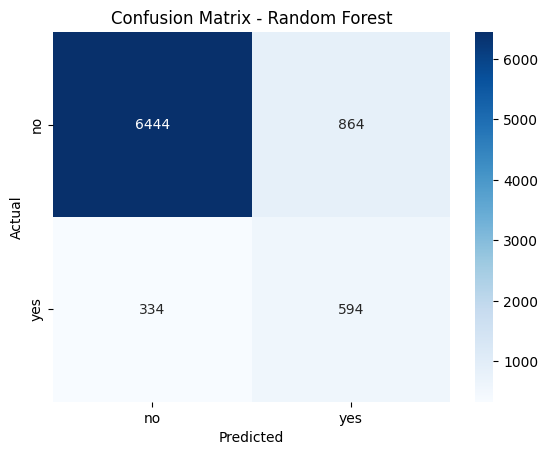

In [97]:
rf_model = evaluate_model(
    "Random Forest",
    RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

Random Forest Model Results
--------------------------------
Accuracy  : 0.8545<br>
Precision : 0.4074<br>
Recall    : 0.6401<br>
F1        : 0.4979<br>
ROC-AUC   : 0.8097<br><br><br>

F1 değeri 0.4979 ile şimdiye kadarki en yüksek. Recall'u yüksek tutarken precision'ı da 0.41'e çıkarabildi. <br>

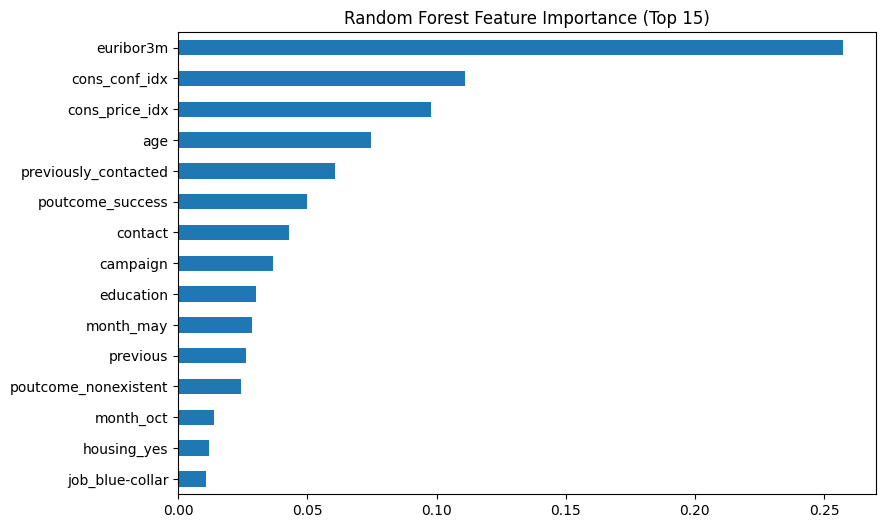

In [98]:
importances = pd.Series(
    rf_model.feature_importances_,
    index=X_train_scaled.columns
).sort_values(ascending=False).head(15)

importances.plot(kind="barh", figsize=(9, 6))
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance (Top 15)")
plt.show()

Random Forest'a göre en önemli feature açık ara euribor3m. Sonra cons_conf_idx ve cons_price_idx geliyor. <br>
Yani müşterinin kendisinden çok o dönemki ekonomik durum kararı etkiliyor. <br>
Sonra age, previously_contacted ve poutcome_success geliyor. <br>

## Hist Gradient Boosting Classifier

sklearn'ün GradientBoosting modeli büyük veride yavaş olduğu için onun hızlı versiyonu olan HistGradientBoosting kullanıldı. <br>
Sayısal değerleri gruplara (histogram) ayırarak çok daha hızlı çalışıyor. <br>

Hist Gradient Boosting Model Results
--------------------------------
Accuracy  : 0.8458
Precision : 0.3911
Recall    : 0.6616
F1        : 0.4916
ROC-AUC   : 0.8149


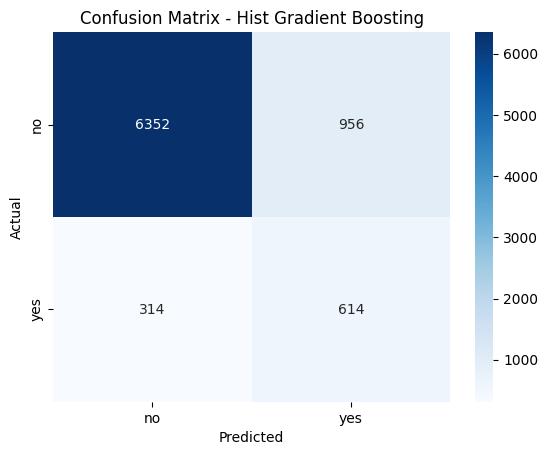

In [99]:
hgb_model = evaluate_model(
    "Hist Gradient Boosting",
    HistGradientBoostingClassifier(
        max_iter=300,
        learning_rate=0.05,
        class_weight="balanced",
        random_state=42
    )
)

Hist Gradient Boosting Model Results
--------------------------------
Accuracy  : 0.8458<br>
Precision : 0.3911<br>
Recall    : 0.6616<br>
F1        : 0.4916<br>
ROC-AUC   : 0.8149<br><br><br>

ROC-AUC 0.8149 ile en yüksek değer. F1 de Random Forest'a çok yakın. <br>


## CatBoost Classifier

CatBoost kategorik sütunları kendisi işleyebildiği için one-hot encoding yapılmamış veri (X_train_raw) kullanıldı. <br>
auto_class_weights="Balanced" ile dengesizlik için ağırlık verildi. <br>

0:	learn: 0.6776883	total: 31ms	remaining: 31s
200:	learn: 0.5166476	total: 3.68s	remaining: 14.6s
400:	learn: 0.4852454	total: 7.65s	remaining: 11.4s
600:	learn: 0.4642034	total: 11.6s	remaining: 7.7s
800:	learn: 0.4456999	total: 16.3s	remaining: 4.04s
999:	learn: 0.4287586	total: 20.4s	remaining: 0us
CatBoost Model Results
--------------------------------
Accuracy  : 0.8493
Precision : 0.3975
Recall    : 0.6541
F1        : 0.4945
ROC-AUC   : 0.8091


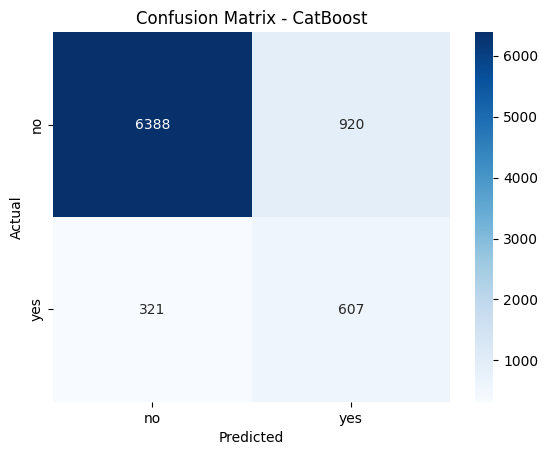

In [100]:
cat_features_list = nominal_features

catboost_model = evaluate_model(
    "CatBoost",
    CatBoostClassifier(
        iterations=1000,
        learning_rate=0.05,
        depth=6,
        cat_features=cat_features_list,
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=200
    ),
    X_train_raw,
    X_test_raw
)

CatBoost Model Results
--------------------------------
Accuracy  : 0.8493<br>
Precision : 0.3975<br>
Recall    : 0.6541<br>
F1        : 0.4945<br>
ROC-AUC   : 0.8091<br><br><br>

Sonuçları Random Forest ve Hist Gradient Boosting ile neredeyse aynı. <br>
Salary verisindeki gibi açık ara öne geçemedi ama one-hot encoding yapmadan da aynı performansı yakaladı. <br>

# Threshold Tuning

Modeller varsayılan olarak olasılık 0.5'in üstündeyse yes diyor. <br>
Bu eşik değiştirilerek precision ve recall arasındaki denge ayarlanabilir. <br>
CatBoost modeli için farklı eşikler denendi. <br>

,Threshold,Precision,Recall,F1
0,0.30,0.1942,0.8125,0.3134
1,0.35,0.2400,0.7608,0.3649
2,0.40,0.2980,0.7220,0.4219
3,0.45,0.3530,0.6832,0.4655
4,0.50,0.3975,0.6541,0.4945
5,0.55,0.4315,0.6347,0.5137
6,0.60,0.4576,0.6110,0.5233
7,0.65,0.4764,0.5873,0.5261
8,0.70,0.4876,0.5528,0.5182
9,0.75,0.5110,0.5000,0.5054


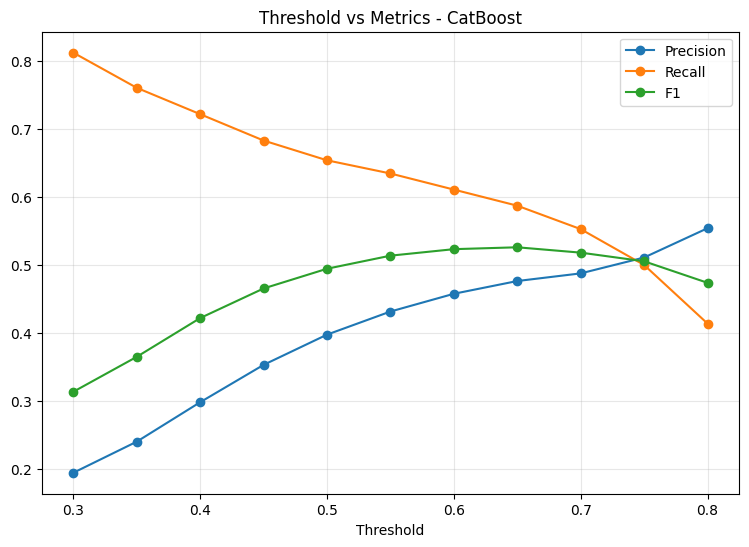

In [101]:
y_proba = catboost_model.predict_proba(X_test_raw)[:, 1]

threshold_results = []

for threshold in np.arange(0.3, 0.85, 0.05):
    y_pred = (y_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred)
    })

threshold_df = pd.DataFrame(threshold_results)
display(threshold_df.round(4))

threshold_df.plot(x="Threshold", y=["Precision", "Recall", "F1"], figsize=(9, 6), marker="o")
plt.title("Threshold vs Metrics - CatBoost")
plt.grid(alpha=0.3)
plt.show()

Eşik düştükçe recall artıyor ama precision düşüyor. Eşik arttıkça tam tersi oluyor. <br>
F1'in en yüksek olduğu nokta 0.65 civarı (F1 = 0.5261). 0.5'teki 0.4945'ten daha iyi. <br><br>
Ama hangi eşiğin seçileceği bankanın amacına bağlı: <br>
- Hiçbir müşteriyi kaçırmak istemiyorsak düşük eşik (0.3-0.4) seçilir, recall %72-81 olur. <br>
- Boşuna arama yapmak istemiyorsak yüksek eşik seçilir, precision artar. <br><br>
Not: eşiği test verisine bakarak seçmek tam doğru değil, normalde ayrı bir validation seti kullanılmalı. Burada sadece etkisini görmek için yapıldı. <br>

# Results

Modellerin karşılaştırılması

In [102]:
results_df = pd.DataFrame(results).T.sort_values(by="ROC-AUC", ascending=False)
display(results_df.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Hist Gradient Boosting,0.8458,0.3911,0.6616,0.4916,0.8149
Random Forest,0.8545,0.4074,0.6401,0.4979,0.8097
CatBoost,0.8493,0.3975,0.6541,0.4945,0.8091
Decision Tree,0.8288,0.3600,0.6681,0.4679,0.8055
Logistic Regression (Balanced),0.8252,0.3512,0.6509,0.4562,0.7981
Logistic Regression,0.8987,0.6588,0.2101,0.3186,0.7958
KNN,0.8963,0.5984,0.2425,0.3451,0.7728
Naive Bayes,0.8731,0.4348,0.4203,0.4274,0.7631


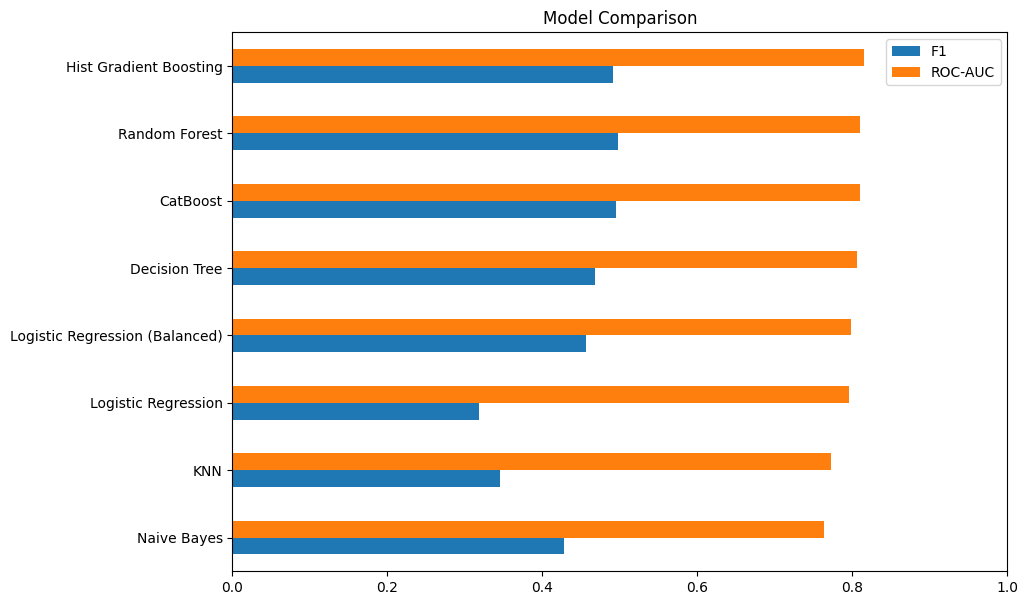

In [103]:
results_df[["F1", "ROC-AUC"]].sort_values(by="ROC-AUC").plot(kind="barh", figsize=(10, 7))
plt.title("Model Comparison")
plt.xlim(0, 1)
plt.show()

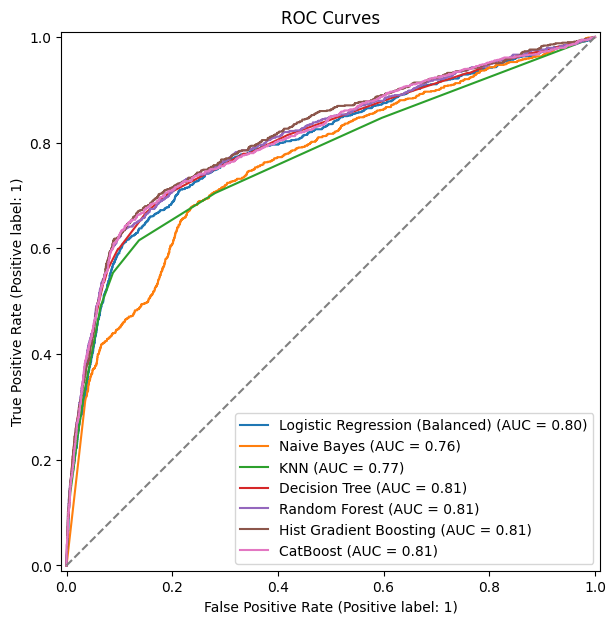

In [104]:
plt.figure(figsize=(9, 7))
ax = plt.gca()

models = {
    "Logistic Regression (Balanced)": (log_balanced_model, X_test_scaled),
    "Naive Bayes": (nb_model, X_test_scaled),
    "KNN": (knn_model, X_test_scaled),
    "Decision Tree": (dt_model, X_test_scaled),
    "Random Forest": (rf_model, X_test_scaled),
    "Hist Gradient Boosting": (hgb_model, X_test_scaled),
    "CatBoost": (catboost_model, X_test_raw)
}

for name, (model, X_te) in models.items():
    RocCurveDisplay.from_estimator(model, X_te, y_test, name=name, ax=ax)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.title("ROC Curves")
plt.show()

Sonuçlar ROC-AUC'a göre büyükten küçüğe sıralandı. <br><br>

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Hist Gradient Boosting | 0.8458 | 0.3911 | 0.6616 | 0.4916 | 0.8149 |
| Random Forest | 0.8545 | 0.4074 | 0.6401 | 0.4979 | 0.8097 |
| CatBoost | 0.8493 | 0.3975 | 0.6541 | 0.4945 | 0.8091 |
| Decision Tree | 0.8288 | 0.3600 | 0.6681 | 0.4679 | 0.8055 |
| Logistic Regression (Balanced) | 0.8252 | 0.3512 | 0.6509 | 0.4562 | 0.7981 |
| Logistic Regression | 0.8987 | 0.6588 | 0.2101 | 0.3186 | 0.7958 |
| KNN | 0.8963 | 0.5984 | 0.2425 | 0.3451 | 0.7728 |
| Naive Bayes | 0.8731 | 0.4348 | 0.4203 | 0.4274 | 0.7631 |

<br>
En yüksek accuracy'yi normal Logistic Regression ve KNN aldı ama bu iki model yes'lerin çoğunu kaçırıyor. Dengesiz veride accuracy'ye bakmanın neden yanıltıcı olduğu burada net görülüyor. <br><br>
Ağaç tabanlı modeller (Hist Gradient Boosting, Random Forest, CatBoost) en iyi sonuçları verdi ve birbirine çok yakınlar. <br><br>
class_weight kullanmak recall'u ciddi artırdı (Logistic Regression'da 0.21'den 0.65'e). <br><br>
Genel olarak skorların çok yüksek olmaması normal. duration sütununu çıkardığımız için model sadece arama öncesi bilinen bilgilerle tahmin yapıyor. duration'ı bıraksaydık ROC-AUC 0.95 civarına çıkıyor (ayrıca denedim) ama gerçek hayatta kullanılamazdı. <br>